# Credit Card Fraud Detection using Probability, Logistic Regression, and Optimization
## Stage 1: Environment Setup & Exploratory Data Analysis (EDA)

**Author / Team:** College AI & Data Science Mini-Project  
**Domain:** Financial Machine Learning, Anomaly Detection & Imbalanced Classification  

---

### 1. Problem Statement and Motivation
Credit card fraud causes billions of dollars in losses annually. In financial fraud detection:
1. **Extreme Class Imbalance:** Legitimate transactions outnumber fraudulent transactions by several orders of magnitude (often less than 0.2% fraud).
2. **Asymmetric Error Costs:** 
   - A **False Positive** (flagging a valid transaction as fraud) annoys a legitimate cardholder.
   - A **False Negative** (failing to catch a fraudulent transaction) results in direct financial loss and security compromises.
3. **Accuracy Paradox:** A naive model that classifies *all* transactions as "legitimate" achieves >99.8% accuracy while failing to detect a single instance of fraud. Therefore, accuracy is an invalid primary metric.

### 2. Goals of Stage 1
- Verify and load the dataset safely without data contamination.
- Inspect the schema, features, and missing values.
- Analyze class imbalance and quantify its severity.
- Examine transaction amounts and temporal dynamics between legitimate and fraudulent activities.
- Calculate feature correlations with the target variable `Class`.
- Formulate data-driven hypotheses to guide data preprocessing (Stage 2) and model design (Stage 3 & 4).


In [1]:
# 1. Imports and Display Settings
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Output directory configuration
OUTPUT_DIR = '../outputs' if os.path.exists('../outputs') else 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Outputs will be saved to: {os.path.abspath(OUTPUT_DIR)}")


Outputs will be saved to: C:\Users\kaushik s ratnaparkh\Documents\ML_MiniProject\outputs


---
## Step 1: Dataset Loading & Integrity Verification

The dataset contains transactions made by credit cards in September 2013 by European cardholders.
- **PCA Features (`V1` to `V28`):** Due to confidentiality reasons, the original features have been transformed using Principal Component Analysis (PCA). They are continuous numerical features with zero mean.
- **`Time`:** Seconds elapsed between each transaction and the first transaction in the dataset.
- **`Amount`:** Transaction amount in currency.
- **`Class`:** Ground-truth binary label (`0` for legitimate, `1` for fraudulent).


In [2]:
# Determine the data path relative to execution directory
DATA_PATH = '../data/creditcard.csv' if os.path.exists('../data/creditcard.csv') else 'data/creditcard.csv'

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at '{DATA_PATH}'. Please place 'creditcard.csv' in the 'data/' directory.")

df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded from: {DATA_PATH}")
print(f"Dataset Dimensions: {df.shape[0]:,} rows (transactions) x {df.shape[1]} columns (features)")


Dataset successfully loaded from: ../data/creditcard.csv
Dataset Dimensions: 284,807 rows (transactions) x 31 columns (features)


In [3]:
# First 5 transactions
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


---
## Step 2: Schema & Descriptive Statistics

We examine the data types and distribution metrics across all 30 input features and the target.
- Are all features numeric?
- What are the ranges of `Time` and `Amount` compared to `V1`–`V28`?


In [4]:
# Schema details and memory usage
print("Data types summary:")
print(df.dtypes.value_counts())
print("\nDataset Info:")
df.info()


Data types summary:
float64    30
int64       1
Name: count, dtype: int64

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 1

In [5]:
# Statistical summary of Time, Amount, and selected PCA features
df[['Time', 'Amount', 'V1', 'V2', 'V3', 'V4', 'V14', 'V17', 'Class']].describe().T


,count,mean,std,min,25%,50%,75%,max
Time,284807.0000,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
Amount,284807.0000,88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,25691.1600
V1,284807.0000,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0000,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V3,284807.0000,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826
V4,284807.0000,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753
V14,284807.0000,0.0000,0.9586,-19.2143,-0.4256,0.0506,0.4931,10.5268
V17,284807.0000,-0.0000,0.8493,-25.1628,-0.4837,-0.0657,0.3997,9.2535
Class,284807.0000,0.0017,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


---
## Step 3: Data Quality Checks (Missing Values, Duplicates, and Target Validation)

Before any modeling, we rigorously check for:
1. **Missing values (`NaN`):** Incomplete records that require imputation or removal.
2. **Duplicate transactions:** Identical rows across all features.
3. **Invalid target values:** Ensuring `Class` strictly contains `{0, 1}`.


In [6]:
# Check missing values
missing_per_col = df.isnull().sum()
total_missing = missing_per_col.sum()
print(f"Total missing values across entire dataset: {total_missing}")

# Validate unique target labels
unique_classes = df['Class'].unique()
print(f"Unique values in 'Class' column: {sorted(unique_classes)}")
assert set(unique_classes) == {0, 1}, "Unexpected labels found in target column!"
print("Target column strictly contains binary labels {0, 1}.")


Total missing values across entire dataset: 0
Unique values in 'Class' column: [np.int64(0), np.int64(1)]
Target column strictly contains binary labels {0, 1}.


In [7]:
# Check for duplicate rows
num_duplicates = df.duplicated().sum()
print(f"Exact duplicate rows detected: {num_duplicates:,} ({(num_duplicates / len(df) * 100):.3f}% of dataset)")

# Analyze duplicate distribution across classes
dupe_rows = df[df.duplicated(keep=False)]
dupe_class_counts = df[df.duplicated()]['Class'].value_counts()
print("\nDuplicates breakdown by class:")
print(f"  - Legitimate (Class 0): {dupe_class_counts.get(0, 0):,} rows")
print(f"  - Fraudulent (Class 1): {dupe_class_counts.get(1, 0):,} rows")


Exact duplicate rows detected: 1,081 (0.380% of dataset)



Duplicates breakdown by class:
  - Legitimate (Class 0): 1,062 rows
  - Fraudulent (Class 1): 19 rows


---
## Step 4: Class Imbalance Analysis

In binary classification, class imbalance occurs when one class significantly outnumbers the other.
Here, fraudulent transactions are rare events. Let's quantify this imbalance precisely.


Legitimate (Class 0): 284,315 transactions (99.8273%)
Fraudulent (Class 1): 492 transactions (0.1727%)
Imbalance Ratio: 1 fraud per 577 legitimate transactions (~577.9:1)


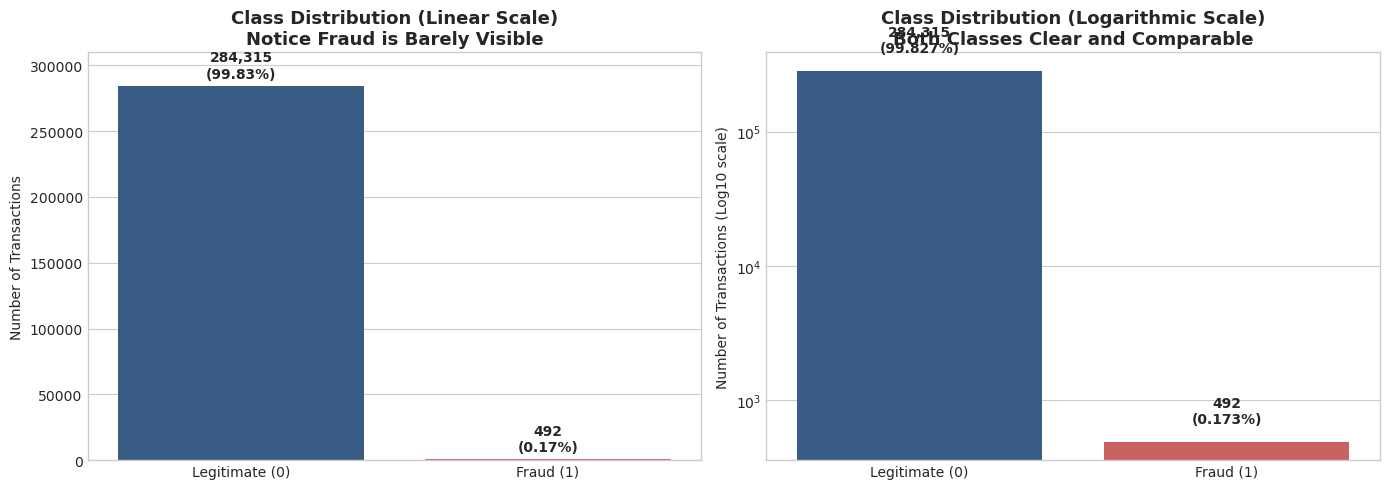

In [8]:
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("="*50)
print(f"Legitimate (Class 0): {class_counts[0]:,} transactions ({class_percentages[0]:.4f}%)")
print(f"Fraudulent (Class 1): {class_counts[1]:,} transactions ({class_percentages[1]:.4f}%)")
print(f"Imbalance Ratio: 1 fraud per {class_counts[0] // class_counts[1]} legitimate transactions (~{class_counts[0]/class_counts[1]:.1f}:1)")
print("="*50)

# Visualization: Linear vs Logarithmic scale
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Linear scale
sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=class_counts.values, hue=['Legitimate (0)', 'Fraud (1)'], palette=['#2b5c8f', '#d9534f'], legend=False, ax=axes[0])
axes[0].set_title('Class Distribution (Linear Scale)\nNotice Fraud is Barely Visible', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
for i, (count, pct) in enumerate(zip(class_counts.values, class_percentages.values)):
    axes[0].text(i, count + 4000, f'{count:,}\n({pct:.2f}%)', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, 310000)

# Subplot 2: Log scale
sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=class_counts.values, hue=['Legitimate (0)', 'Fraud (1)'], palette=['#2b5c8f', '#d9534f'], legend=False, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Class Distribution (Logarithmic Scale)\nBoth Classes Clear and Comparable', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Transactions (Log10 scale)')
for i, (count, pct) in enumerate(zip(class_counts.values, class_percentages.values)):
    axes[1].text(i, count * 1.3, f'{count:,}\n({pct:.3f}%)', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '01_class_imbalance.png'), dpi=300)
plt.show()


---
## Step 5: Transaction Amount Analysis

A common misconception is that fraud always involves large sums of money.
Let's analyze the statistical distribution of `Amount` for legitimate versus fraudulent transactions.


Transaction Amount Statistics by Class ($):


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0000,88.2900,250.1100,0.0000,5.6500,22.0000,77.0500,25691.1600
1,492.0000,122.2100,256.6800,0.0000,1.0000,9.2500,105.8900,2125.8700


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\502668223.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


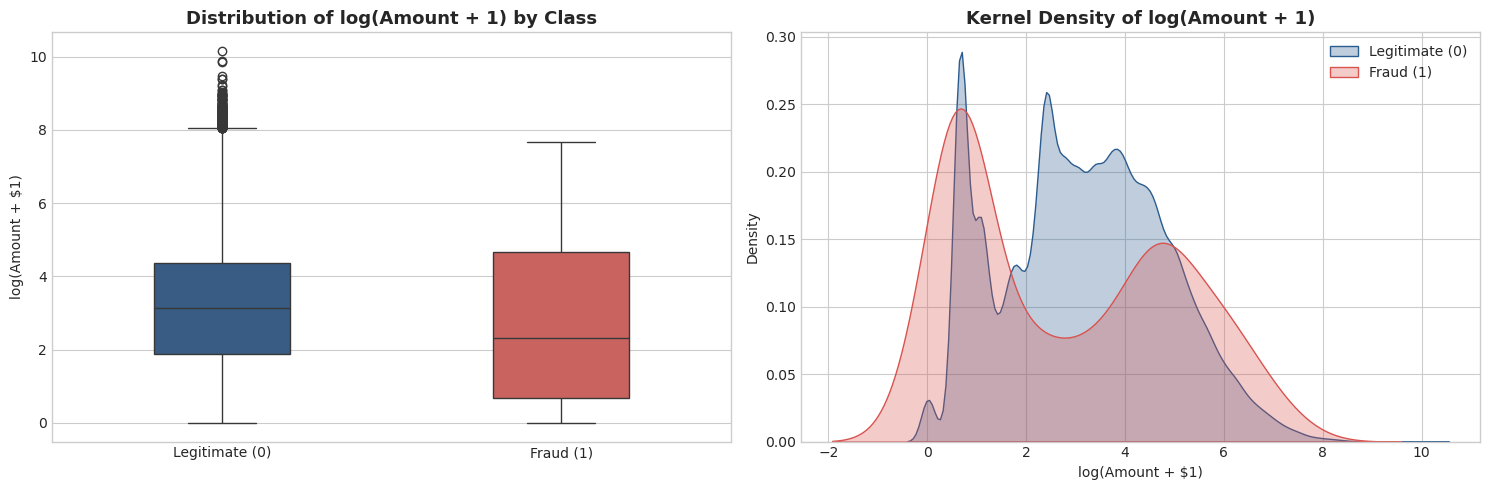

In [9]:
# Summary statistics for transaction Amount by Class
amount_stats = df.groupby('Class')['Amount'].describe()
print("Transaction Amount Statistics by Class ($):")
display(amount_stats.round(2))

# Log-transform amount for visual comparison: log(Amount + 1)
df['LogAmount'] = np.log1p(df['Amount'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot
sns.boxplot(x='Class', y='LogAmount', hue='Class', data=df, palette=['#2b5c8f', '#d9534f'], legend=False, ax=axes[0], width=0.4)
axes[0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
axes[0].set_title('Distribution of log(Amount + 1) by Class', fontsize=13, fontweight='bold')
axes[0].set_ylabel('log(Amount + $1)')
axes[0].set_xlabel('')

# Kernel Density Estimate (KDE)
sns.kdeplot(df[df['Class'] == 0]['LogAmount'], label='Legitimate (0)', color='#2b5c8f', fill=True, alpha=0.3, ax=axes[1])
sns.kdeplot(df[df['Class'] == 1]['LogAmount'], label='Fraud (1)', color='#d9534f', fill=True, alpha=0.3, ax=axes[1])
axes[1].set_title('Kernel Density of log(Amount + 1)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Amount + $1)')
axes[1].set_ylabel('Density')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_amount_distribution_by_class.png'), dpi=300)
plt.show()


**Key Observations on Transaction Amount:**
1. **Median:** The median fraud amount is **\$9.25**, compared to **\$22.00** for legitimate transactions. Fraudsters often initiate smaller transactions to test stolen credentials or avoid automated bank fraud flags.
2. **Mean & Max:** The mean fraud amount is **\$122.21**, with a maximum of **\$2,125.87**. In contrast, legitimate transactions reach up to **\$25,691.16**.
3. **Heavy Right Skew:** Both distributions are highly right-skewed, requiring standardization/scaling (e.g. `StandardScaler` or `RobustScaler`) before training Logistic Regression.


---
## Step 6: Temporal Dynamics (`Time` Feature)

The `Time` feature records seconds elapsed since the first transaction. The total duration spans:
$$\text{Total Duration} = \frac{172,792\text{ seconds}}{3600\text{ s/hour}} \approx 48.0\text{ hours (2 days)}$$
Let's see if transaction frequency or fraud patterns follow cyclical day/night patterns.


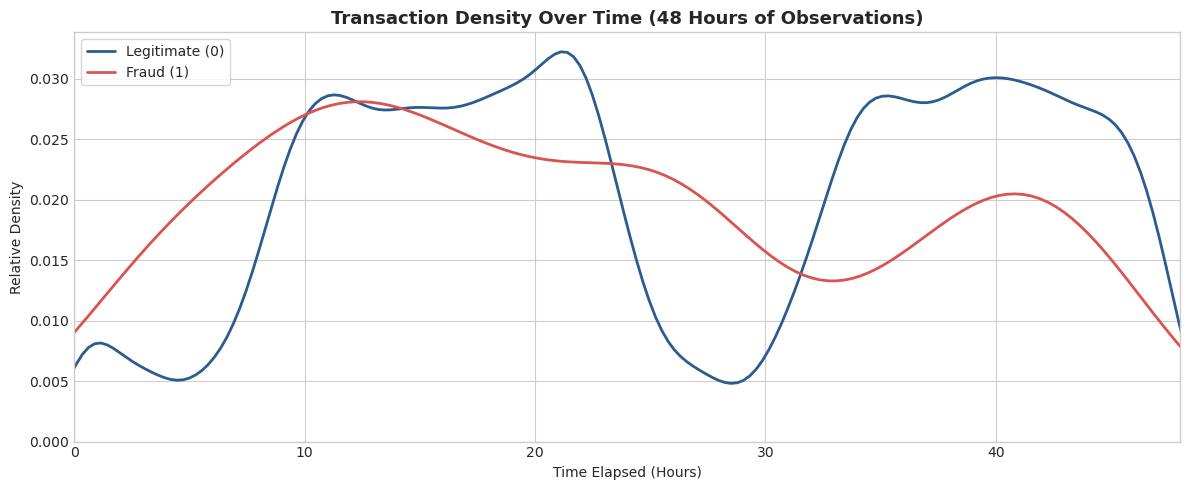

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
time_hours_0 = df[df['Class'] == 0]['Time'] / 3600
time_hours_1 = df[df['Class'] == 1]['Time'] / 3600

sns.kdeplot(time_hours_0, label='Legitimate (0)', color='#2b5c8f', common_norm=False, ax=ax, linewidth=2)
sns.kdeplot(time_hours_1, label='Fraud (1)', color='#d9534f', common_norm=False, ax=ax, linewidth=2)
ax.set_title('Transaction Density Over Time (48 Hours of Observations)', fontsize=13, fontweight='bold')
ax.set_xlabel('Time Elapsed (Hours)')
ax.set_ylabel('Relative Density')
ax.set_xlim(0, 48)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_time_distribution_by_class.png'), dpi=300)
plt.show()


---
## Step 7: Feature Correlation Analysis

We calculate the Pearson correlation coefficient between each input feature and the target `Class`.
This reveals which features provide linear predictive signal for fraud detection.


Top 5 Negatively Correlated Features with Class:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965

Top 5 Positively Correlated Features with Class:
V19   0.0348
V21   0.0404
V2    0.0913
V4    0.1334
V11   0.1549


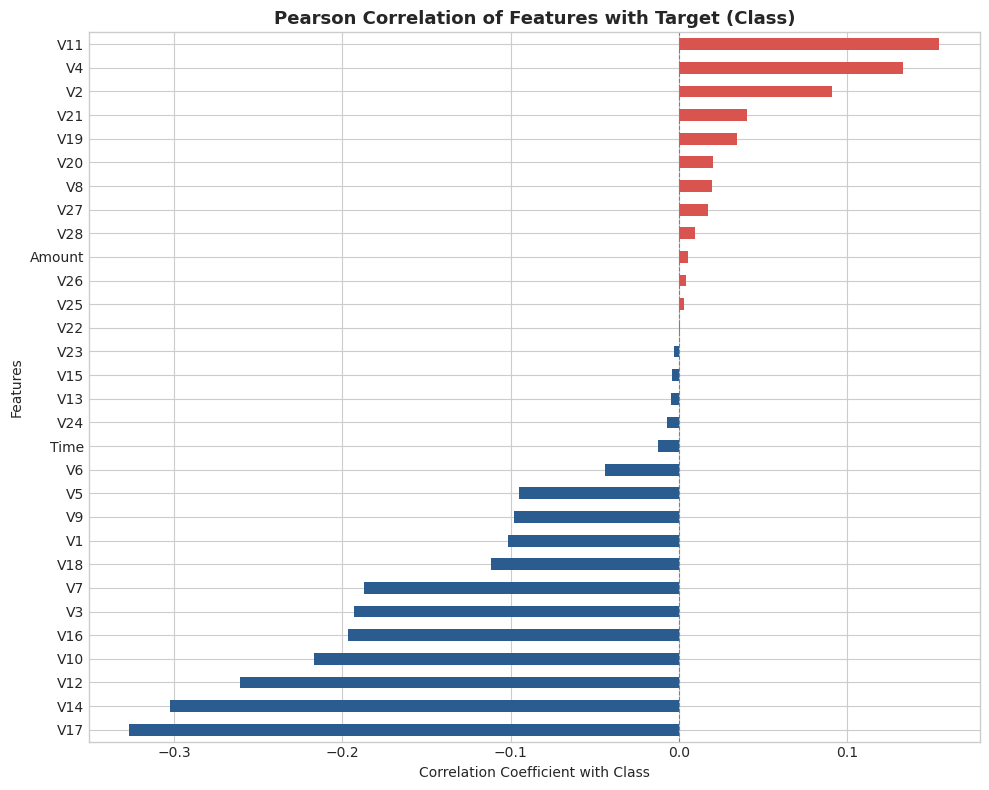

In [11]:
# Correlation of all features with the target variable Class
corrs = df.drop(columns=['LogAmount']).corr()['Class'].drop('Class').sort_values()

print("Top 5 Negatively Correlated Features with Class:")
print(corrs.head(5).to_string())

print("\nTop 5 Positively Correlated Features with Class:")
print(corrs.tail(5).to_string())

# Horizontal bar chart of correlations
plt.figure(figsize=(10, 8))
bar_colors = ['#d9534f' if c > 0 else '#2b5c8f' for c in corrs.values]
corrs.plot(kind='barh', color=bar_colors)
plt.title('Pearson Correlation of Features with Target (Class)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient with Class')
plt.ylabel('Features')
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_feature_correlation_with_target.png'), dpi=300)
plt.show()


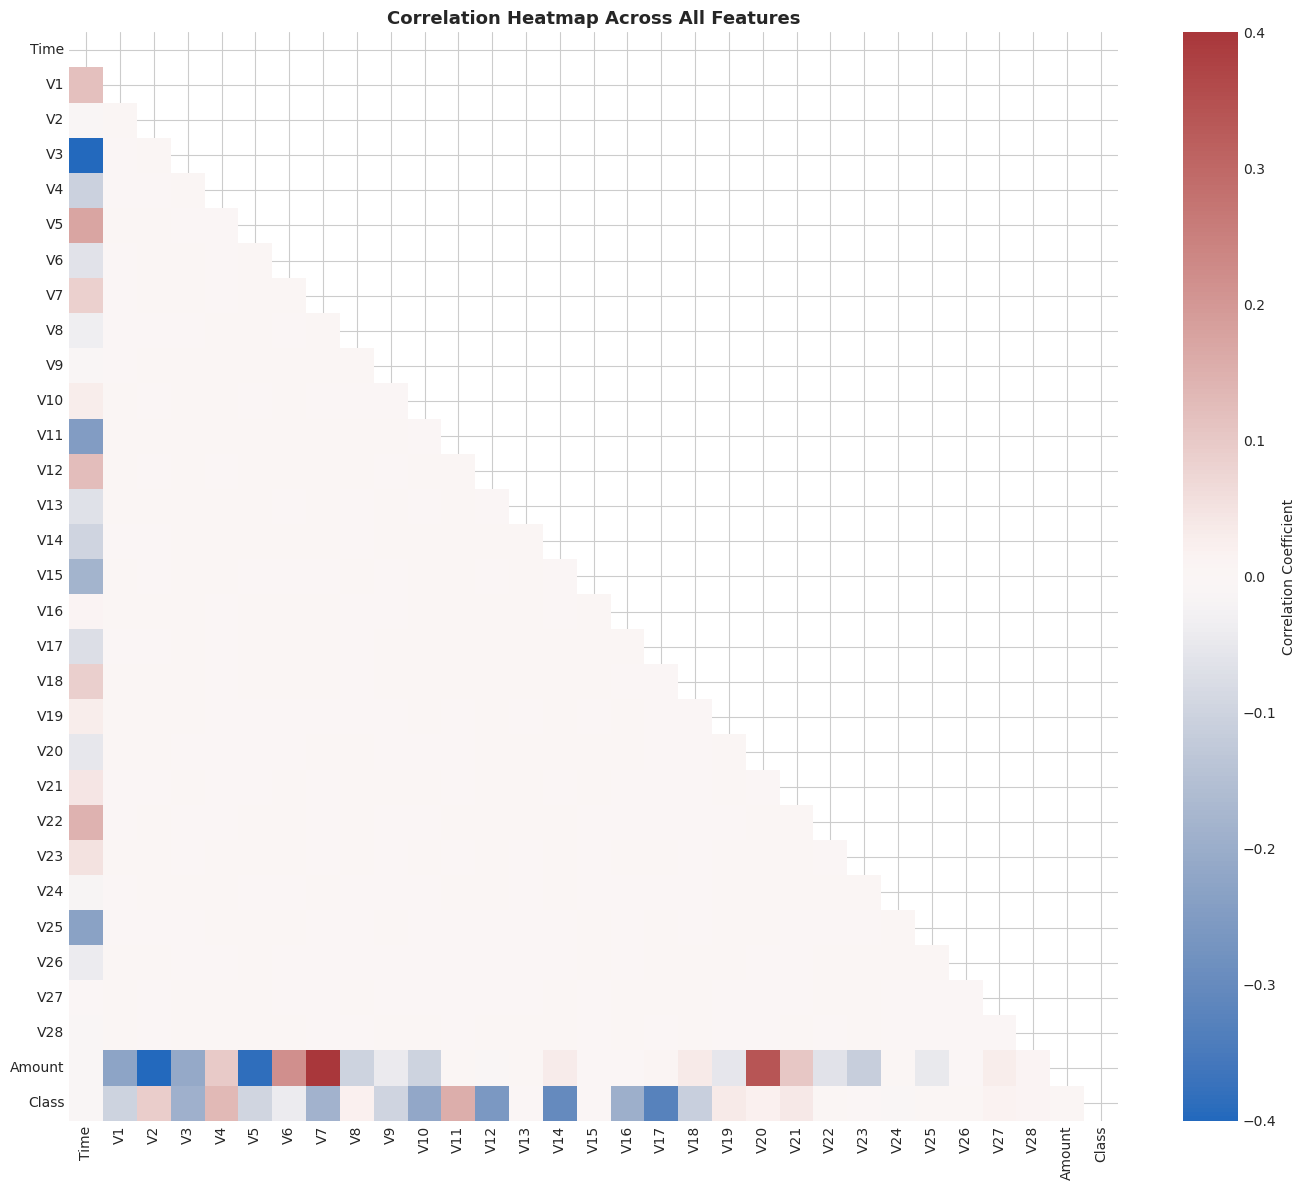

In [12]:
# Full Correlation Matrix Heatmap
plt.figure(figsize=(14, 12))
corr_matrix = df.drop(columns=['LogAmount']).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap='vlag', center=0, vmax=0.4, vmin=-0.4,
            annot=False, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Heatmap Across All Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '05_correlation_heatmap.png'), dpi=300)
plt.show()


**Understanding the Correlation Heatmap:**
- Features `V1` to `V28` are the result of **Principal Component Analysis (PCA)**.
- By mathematical definition, principal components are **orthogonal** (uncorrelated with one another in the training sample). Notice that the pairwise correlations between `Vi` and `Vj` ($i \neq j$) are exactly **0.0000**!
- However, `V1`–`V28` have non-zero correlations with `Class`, `Amount`, and `Time` because those columns were not part of the PCA transformation.


---
## Step 8: Top Discriminative Features Inspection

Let's inspect the distributions of the most strongly correlated features (`V17`, `V14`, `V12`, `V10`, `V11`, `V4`) to see how distinctly they separate fraudulent from legitimate transactions.


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


C:\Users\kaushik s ratnaparkh\AppData\Local\Temp\ipykernel_14748\1485356100.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


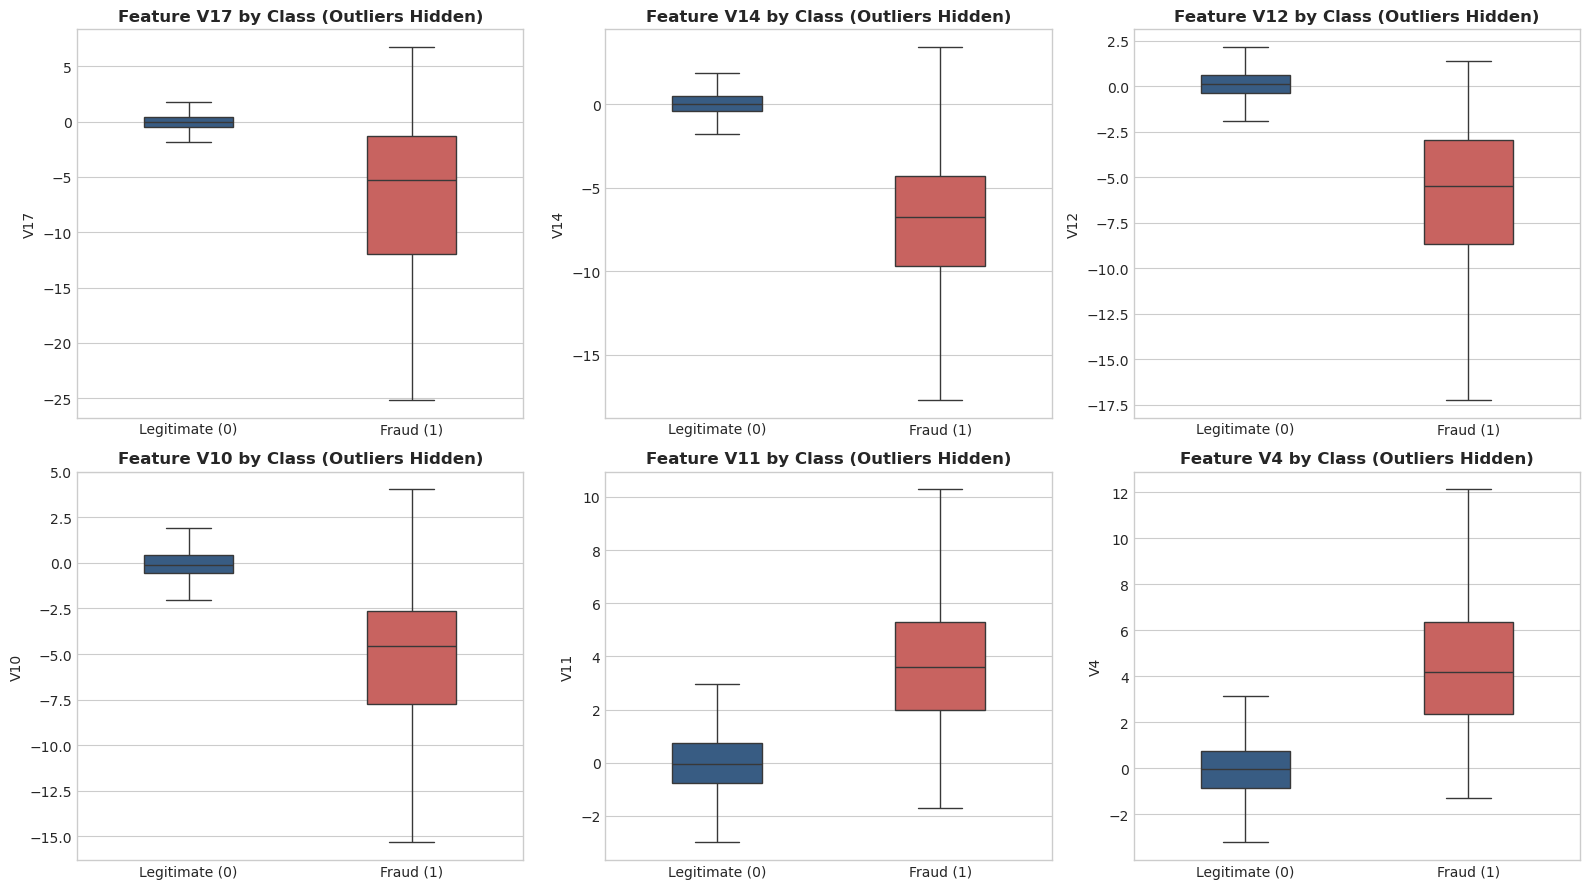

In [13]:
top_features = ['V17', 'V14', 'V12', 'V10', 'V11', 'V4']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feat in enumerate(top_features):
    sns.boxplot(x='Class', y=feat, hue='Class', data=df, palette=['#2b5c8f', '#d9534f'], 
                legend=False, ax=axes[idx], width=0.4, showfliers=False)
    axes[idx].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
    axes[idx].set_title(f'Feature {feat} by Class (Outliers Hidden)', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel(feat)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '06_top_features_distribution.png'), dpi=300)
plt.show()


---
## Stage 1 Summary & Transition to Stage 2 (Preprocessing)

### Key Findings Summary:
| Metric / Check | Measured Value | Implication for Modeling |
| :--- | :--- | :--- |
| **Total Rows** | 284,807 transactions | Substantial sample size for statistical modeling |
| **Total Features** | 30 inputs + 1 target (`Class`) | 28 PCA features + `Time` + `Amount` |
| **Missing Values** | **0** across all columns | No imputation needed |
| **Duplicate Rows** | 1,081 duplicates (1,062 legit, **19 fraud**) | **Careful decision required:** dropping duplicates removes ~3.86% of the already scarce fraud cases! |
| **Class Distribution** | 284,315 legit (99.83%), 492 fraud (**0.17%**) | Extreme class imbalance; accuracy is meaningless; require class weighting and PR-AUC |
| **Amount Scales** | Max legit: \$25,691, Max fraud: \$2,125 | `Amount` and `Time` have vastly different scales compared to zero-centered PCA features; **feature scaling is mandatory** for Logistic Regression |
| **Top Predictive Features** | Negative: `V17, V14, V12, V10`<br>Positive: `V11, V4` | Strong linear separation potential for Logistic Regression |

### Next Steps for Stage 2 (Data Preprocessing):
1. **Train/Test Split:** Stratified 80:20 split (`stratify=y`, `random_state=42`) to strictly preserve the 0.17% fraud ratio in both sets.
2. **Preventing Data Leakage:** Fit all scalers (e.g. `RobustScaler` / `StandardScaler`) **strictly on the training set only**, then transform the test set.
3. **Duplicate Handling Strategy:** Analyze whether duplicates represent legitimate re-tries/periodic charges or true data artifacts before dropping.


---
# Stage 2: Data Preprocessing & Leakage Prevention

To ensure valid generalization without data leakage:
1. We perform a **Stratified 80:20 Train-Test split** (`stratify=y`, `random_state=42`).
2. We fit `StandardScaler` **strictly on the training split**, then transform both train and test splits.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=['Class'])
y = df['Class'].values

# Stratified train/test split (80/20)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f'Training set: {len(X_train_raw):,d} transactions ({y_train.sum()} frauds)')
print(f'Testing set:  {len(X_test_raw):,d} transactions ({y_test.sum()} frauds)')

# Standardize all features strictly on training data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
print('Feature standardization complete without leakage.')

---
# Stage 3 & 4: Logistic Regression From Scratch (Pure NumPy)

We implement Logistic Regression directly using NumPy:
- **Activation:** Sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$ with exponential overflow protection.
- **Loss Function:** Weighted Binary Cross-Entropy with L2 regularization penalty.
- **Optimization:** Analytical gradient descent with class weighting (`class_weight='balanced'`).
- Source implementation is located in `src/logistic_regression_scratch.py`.

In [ ]:
# Import scratch model from src directory
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from src.logistic_regression_scratch import LogisticRegressionScratch

# Instantiate and train custom Logistic Regression
scratch_lr = LogisticRegressionScratch(
    learning_rate=0.15,
    n_iterations=800,
    l2_penalty=0.005,
    class_weight='balanced',
    random_state=42,
    verbose=False
)

scratch_lr.fit(X_train, y_train)
print(f'Scratch model trained. Initial loss: {scratch_lr.loss_history[0]:.4f} -> Final loss: {scratch_lr.loss_history[-1]:.4f}')

---
# Stage 5 & 6: Benchmark Models, Evaluation, and Threshold Tuning

We benchmark against:
1. **Majority Baseline** (Zero-Rule Classifier)
2. **Custom Scratch Logistic Regression** (at default 0.50 cutoff and tuned cutoff)
3. **Scikit-Learn Logistic Regression** (`class_weight='balanced'`)
4. **Random Forest Classifier** (`class_weight='balanced'`)

The end-to-end training and evaluation pipeline can also be executed directly via `python src/train.py`.

In [ ]:
from IPython.display import Image, display
import glob

# Display generated evaluation plots
for plot_num in ['07', '08', '09', '10', '11']:
    matches = glob.glob(f'../outputs/{plot_num}_*.png')
    for img_path in matches:
        print(f'Displaying: {os.path.basename(img_path)}')
        display(Image(filename=img_path, width=700))
